In [1]:

!pip -q install timm scikit-learn pandas matplotlib tqdm pillow

from google.colab import drive, files
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import os, zipfile, shutil, glob, random, gc, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)
import timm

drive.mount("/content/drive")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

if device.type != "cuda":
    raise RuntimeError(
        "Enable GPU: Runtime > Change runtime type > GPU."
    )

ROOT = "/content/drive/MyDrive/DR_Project"
STAGE1_W = (
    ROOT + "/stage1/weights/"
    "stage1_original_fixed_best_dr_b0.pth"
)
IMAGE_DIR = (
    "/content/drive/MyDrive/Dataset_extracted/"
    "colored_images/colored_images"
)
SPLIT_DIR = ROOT + "/splits"

OUT_DIR = ROOT + "/stage3_ablation_B4_predicted_mask_SE"
CKPT = OUT_DIR + "/stage3_B4_predicted_mask_SE_best.pth"
HISTORY = OUT_DIR + "/stage3_B4_predicted_mask_SE_history.csv"

os.makedirs(OUT_DIR, exist_ok=True)

assert os.path.isfile(STAGE1_W), (
    "Missing Stage 1 weights: " + STAGE1_W
)
assert os.path.isdir(IMAGE_DIR), (
    "Missing RGB image folder: " + IMAGE_DIR
)

print("Upload the stage3_local.zip used in your predicted-mask notebook.")
uploaded = files.upload()
zips = [n for n in uploaded if n.lower().endswith(".zip")]
assert len(zips) == 1, "Upload exactly one ZIP file."

EXTRACT = Path("/content/stage3_predicted_ablation_data")
EXTRACT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zips[0]) as archive:
    archive.extractall(EXTRACT)

mask_dirs = [
    p for p in EXTRACT.rglob("*")
    if p.is_dir() and p.name.lower() == "stage2_masks"
]

assert len(mask_dirs) == 1, (
    "Expected exactly one stage2_masks folder in the ZIP."
)

STAGE2_MASK_DIR = mask_dirs[0]

print("Stage 2 predicted masks:", STAGE2_MASK_DIR)
print("Output folder:", OUT_DIR)


Mounted at /content/drive
Device: cuda
Upload the stage3_local.zip used in your predicted-mask notebook.


Saving stage3_local.zip to stage3_local.zip
Stage 2 predicted masks: /content/stage3_predicted_ablation_data/stage3_local/dr2015_structured/stage2_masks
Output folder: /content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE


In [3]:
assert 'STAGE2_MASK_DIR' in globals(), 'Run your current Cell 1 first.'
STAGE3_LOCAL = str(STAGE2_MASK_DIR.parent.parent)
print('Original Stage3 data root:', STAGE3_LOCAL)


Original Stage3 data root: /content/stage3_predicted_ablation_data/stage3_local


In [6]:
import os
import gc
import copy
import shutil
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AMP_DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed fixed: {SEED}")


STAGE3_SIZE = 384
STAGE3_BATCH = 64
STAGE3_NUM_WORKERS = 8

PIN_MEMORY = torch.cuda.is_available()

STAGE3_LOCAL = str(STAGE2_MASK_DIR.parent.parent)

RESULTS_DIR = os.path.join(
    OUT_DIR,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

CLASS_NAMES = [
    "no_dr",
    "mild",
    "moderate",
    "severe",
    "proliferative_dr"
]

num_classes = len(CLASS_NAMES)

print(f"Results dir       : {RESULTS_DIR}")
print(f"Classes           : {CLASS_NAMES}")

Device: cuda
Seed fixed: 42
Results dir       : /content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/results
Classes           : ['no_dr', 'mild', 'moderate', 'severe', 'proliferative_dr']


In [5]:
STAGE1_W = "/content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth"



stage1 = timm.create_model(
    "tf_efficientnet_b0.ns_jft_in1k",
    pretrained=False,
    num_classes=num_classes
)

stage1.load_state_dict(torch.load(STAGE1_W, map_location=device))
stage1 = stage1.to(device)
stage1.eval()

for p in stage1.parameters():
    p.requires_grad = False

print("Stage1 loaded")

Stage1 loaded


In [7]:
import os
import shutil
import time

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset_extracted/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"

COPY_COMPLETE_FILE = "/content/.dr_images_copy_complete"

MAX_WORKERS = 8
MAX_RETRIES = 5


os.makedirs(
    LOCAL_IMAGE_ROOT,
    exist_ok=True
)


if not os.path.exists(DRIVE_IMAGE_ROOT):
    raise RuntimeError(
        f"Google Drive folder not found:\n{DRIVE_IMAGE_ROOT}"
    )


print("Scanning files...")


all_files = []

for root, dirs, filenames in os.walk(
    DRIVE_IMAGE_ROOT
):

    for filename in filenames:

        src = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            src,
            DRIVE_IMAGE_ROOT
        )

        dst = os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

        all_files.append(
            (src, dst)
        )


print(
    f"Total files: {len(all_files):,}"
)


remaining_files = []


for src, dst in tqdm(
    all_files,
    desc="Checking existing files",
    unit="file"
):

    try:

        if os.path.exists(dst):

            src_size = os.path.getsize(src)
            dst_size = os.path.getsize(dst)

            if src_size == dst_size:
                continue

            os.remove(dst)

        remaining_files.append(
            (src, dst)
        )

    except Exception:

        remaining_files.append(
            (src, dst)
        )


already_complete = (
    len(all_files)
    -
    len(remaining_files)
)


print(
    f"\nAlready copied correctly: {already_complete:,}"
)

print(
    f"Remaining to copy: {len(remaining_files):,}"
)


def copy_with_retry(item):

    src, dst = item

    os.makedirs(
        os.path.dirname(dst),
        exist_ok=True
    )

    last_error = None


    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        try:

            if os.path.exists(dst):

                try:

                    if (
                        os.path.getsize(src)
                        ==
                        os.path.getsize(dst)
                    ):
                        return True, src, None

                except Exception:
                    pass


                try:
                    os.remove(dst)
                except Exception:
                    pass


            shutil.copyfile(
                src,
                dst
            )


            if (
                os.path.getsize(src)
                !=
                os.path.getsize(dst)
            ):

                raise IOError(
                    "Copied file size does not match source."
                )


            return True, src, None


        except Exception as e:

            last_error = e


            try:
                if os.path.exists(dst):
                    os.remove(dst)
            except Exception:
                pass


            time.sleep(
                min(
                    attempt * 2,
                    10
                )
            )


    return (
        False,
        src,
        str(last_error)
    )


errors = []


with ThreadPoolExecutor(
    max_workers=MAX_WORKERS
) as executor:

    futures = [
        executor.submit(
            copy_with_retry,
            item
        )
        for item in remaining_files
    ]


    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying DR images",
        unit="file"
    ):

        success, src, error = (
            future.result()
        )


        if not success:

            errors.append(
                {
                    "file": src,
                    "error": error
                }
            )


print("\n" + "=" * 70)
print("COPY CHECK")
print("=" * 70)


if errors:

    print(
        f"Files still failed after retries: "
        f"{len(errors):,}"
    )

    print("\nFirst few failed files:")

    for item in errors[:10]:

        print(
            item["file"]
        )

        print(
            item["error"]
        )

    print(
        "\nRun this same cell again. "
        "It will skip all successfully copied files "
        "and retry only the remaining files."
    )

else:

    with open(
        COPY_COMPLETE_FILE,
        "w"
    ) as f:

        f.write("complete")


    print(
        "All DR images copied successfully."
    )

    print(
        "Local folder:",
        LOCAL_IMAGE_ROOT
    )

Scanning files...
Total files: 35,126


Checking existing files:   0%|          | 0/35126 [00:00<?, ?file/s]


Already copied correctly: 0
Remaining to copy: 35,126


Copying DR images:   0%|          | 0/35126 [00:00<?, ?file/s]


COPY CHECK
All DR images copied successfully.
Local folder: /content/dr_images


In [8]:
import os
import glob
import pandas as pd

STAGE3_LOCAL = str(STAGE2_MASK_DIR.parent.parent)

REQUIRED_STAGE3_COLUMNS = {
    "img_path",
    "label",
    "stage3_mask_path"
}

csv_candidates = glob.glob(
    os.path.join(
        STAGE3_LOCAL,
        "**",
        "*.csv"
    ),
    recursive=True
)

stage3_csv = None

for c in csv_candidates:

    try:
        columns = set(
            pd.read_csv(
                c,
                nrows=0
            ).columns
        )
    except Exception:
        continue

    if REQUIRED_STAGE3_COLUMNS.issubset(columns):
        stage3_csv = c
        break


if stage3_csv is None:
    raise RuntimeError(
        "Stage3 CSV not found inside /content/stage3_local"
    )


df_stage3 = pd.read_csv(
    stage3_csv
)

# ONLY changed input: use the Stage 2 predicted-mask CSV column.
assert "stage2_mask_path" in df_stage3.columns, (
    "Original CSV has no stage2_mask_path column."
)

# Because your current ZIP was extracted to EXTRACT, not /content,
# resolve each CSV predicted-mask filename inside the uploaded folder.
mask_files = [p for p in STAGE2_MASK_DIR.rglob('*') if p.is_file()]
mask_lookup = {}
for p in mask_files:
    if p.name in mask_lookup:
        raise RuntimeError('Duplicate Stage 2 mask filename: ' + p.name)
    mask_lookup[p.name] = str(p)

df_stage3['stage3_mask_path'] = (
    df_stage3['stage2_mask_path'].fillna('').astype(str)
    .map(lambda p: mask_lookup.get(os.path.basename(p.strip())))
)
if df_stage3['stage3_mask_path'].isna().any():
    n = int(df_stage3['stage3_mask_path'].isna().sum())
    raise RuntimeError(f'{n} Stage 2 predicted-mask filenames not found in ZIP.')
print('Stage 2 predicted masks selected:', len(df_stage3))


DRIVE_IMAGE_ROOT = (
    "/content/drive/MyDrive/"
    "Dataset_extracted/colored_images/colored_images"
)

LOCAL_IMAGE_ROOT = "/content/dr_images"


def convert_image_path_to_local(path):

    path = str(path).strip()

    if path.startswith(DRIVE_IMAGE_ROOT):

        relative_path = os.path.relpath(
            path,
            DRIVE_IMAGE_ROOT
        )

        return os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

    return path


df_stage3["img_path"] = (
    df_stage3["img_path"]
    .apply(convert_image_path_to_local)
)


df_stage3["stage3_mask_path"] = (
    df_stage3["stage3_mask_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)


if not df_stage3['img_path'].map(os.path.exists).all():
    raise RuntimeError('Some RGB image files are not present after copying.')
if not df_stage3['stage3_mask_path'].map(os.path.exists).all():
    raise RuntimeError('Some Stage 2 predicted masks are missing.')
# Keep every original row: do not silently discard test images.
df_stage3 = df_stage3.copy()


df_stage3["label"] = (
    df_stage3["label"]
    .astype(int)
)


df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)


df_stage3 = df_stage3.reset_index(
    drop=True
)


print("Rows:", len(df_stage3))
print(df_stage3.head())

Stage 2 predicted masks selected: 35126
Rows: 35126
                                  img_path  label  \
0  /content/dr_images/Mild/34350_right.png      1   
1  /content/dr_images/Mild/34364_right.png      1   
2   /content/dr_images/Mild/34368_left.png      1   
3   /content/dr_images/Mild/34382_left.png      1   
4   /content/dr_images/Mild/34405_left.png      1   

                                    stage2_mask_path  \
0  /content/stage3_local/dr2015_structured/stage2...   
1  /content/stage3_local/dr2015_structured/stage2...   
2  /content/stage3_local/dr2015_structured/stage2...   
3  /content/stage3_local/dr2015_structured/stage2...   
4  /content/stage3_local/dr2015_structured/stage2...   

                                    stage3_mask_path         basename  
0  /content/stage3_predicted_ablation_data/stage3...  34350_right.png  
1  /content/stage3_predicted_ablation_data/stage3...  34364_right.png  
2  /content/stage3_predicted_ablation_data/stage3...   34368_left.png  
3  /

In [9]:
SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

def load_names(filename):
    path = os.path.join(
        SPLIT_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with open(path, "r") as f:
        return set(
            line.strip()
            for line in f
            if line.strip()
        )

stage1_train_names = load_names(
    "stage1_train_names.txt"
)

stage1_val_names = load_names(
    "stage1_val_names.txt"
)

stage1_test_names = load_names(
    "stage1_test_names.txt"
)

df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)

available_names = set(
    df_stage3["basename"].astype(str)
)

missing_train = (
    stage1_train_names
    -
    available_names
)

missing_val = (
    stage1_val_names
    -
    available_names
)

missing_test = (
    stage1_test_names
    -
    available_names
)

if missing_train:
    raise RuntimeError(
        f"{len(missing_train)} Stage1 train images "
        "are missing from Stage3 data."
    )

if missing_val:
    raise RuntimeError(
        f"{len(missing_val)} Stage1 validation images "
        "are missing from Stage3 data."
    )

if missing_test:
    raise RuntimeError(
        f"{len(missing_test)} Stage1 test images "
        "are missing from Stage3 data."
    )

if stage1_train_names & stage1_val_names:
    raise RuntimeError(
        "Stage1 train and validation overlap."
    )

if stage1_train_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 train and test overlap."
    )

if stage1_val_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 validation and test overlap."
    )

train_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_train_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_val_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_test_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

train_names = set(
    train_df["basename"].astype(str)
)

val_names = set(
    val_df["basename"].astype(str)
)

test_names = set(
    test_df["basename"].astype(str)
)

if train_names != stage1_train_names:
    raise RuntimeError(
        "Stage3 train images do not exactly "
        "match Stage1 train images."
    )

if val_names != stage1_val_names:
    raise RuntimeError(
        "Stage3 validation images do not exactly "
        "match Stage1 validation images."
    )

if test_names != stage1_test_names:
    raise RuntimeError(
        "Stage3 test images do not exactly "
        "match Stage1 test images."
    )

assigned_names = (
    train_names
    |
    val_names
    |
    test_names
)

if assigned_names != available_names:
    raise RuntimeError(
        "Stage1 split files do not exactly cover "
        "the available Stage3 dataset."
    )

print("=" * 70)
print("STAGE1 / STAGE3 IDENTICAL SPLIT")
print("=" * 70)

print(
    "Total dataset :",
    len(df_stage3)
)

print(
    "Train         :",
    len(train_df)
)

print(
    "Validation    :",
    len(val_df)
)

print(
    "Test          :",
    len(test_df)
)

print()
print(
    "Train-Val overlap :",
    len(train_names & val_names)
)

print(
    "Train-Test overlap:",
    len(train_names & test_names)
)

print(
    "Val-Test overlap  :",
    len(val_names & test_names)
)

print()
print(
    "Same Stage1/Stage3 train:",
    train_names == stage1_train_names
)

print(
    "Same Stage1/Stage3 val  :",
    val_names == stage1_val_names
)

print(
    "Same Stage1/Stage3 test :",
    test_names == stage1_test_names
)

print()
print("Train class counts:")

train_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(train_counts.get(i, 0)):>5}"
    )

print()
print("Validation class counts:")

val_counts = (
    val_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(val_counts.get(i, 0)):>5}"
    )

print()
print("Test class counts:")

test_counts = (
    test_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(test_counts.get(i, 0)):>5}"
    )

STAGE1 / STAGE3 IDENTICAL SPLIT
Total dataset : 35126
Train         : 24588
Validation    : 5269
Test          : 5269

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0

Same Stage1/Stage3 train: True
Same Stage1/Stage3 val  : True
Same Stage1/Stage3 test : True

Train class counts:
no_dr                 : 18067
mild                  :  1710
moderate              :  3704
severe                :   611
proliferative_dr      :   496

Validation class counts:
no_dr                 :  3871
mild                  :   367
moderate              :   794
severe                :   131
proliferative_dr      :   106

Test class counts:
no_dr                 :  3872
mild                  :   366
moderate              :   794
severe                :   131
proliferative_dr      :   106


In [10]:
# DATASET + DATALOADERS

import random as _random
import torchvision.transforms.functional as TF


_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


class DRStage3Dataset(Dataset):

    def __init__(
        self,
        df,
        size=384,
        augment=False
    ):
        self.df = df.reset_index(drop=True)
        self.size = size
        self.augment = augment


    def __len__(self):
        return len(self.df)


    def _load_rgb(self, path):

        img = Image.open(path).convert("RGB")

        img = img.resize(
            (self.size, self.size),
            Image.BILINEAR
        )

        return img


    def _load_mask(self, path):

        mask = Image.open(path).convert("L")

        mask = mask.resize(
            (self.size, self.size),
            Image.NEAREST
        )

        return mask


    def _augment(
        self,
        img_pil,
        mask_pil
    ):

        # Horizontal flip
        if _random.random() > 0.5:

            img_pil = TF.hflip(img_pil)

            mask_pil = TF.hflip(mask_pil)


        # Vertical flip
        if _random.random() > 0.5:

            img_pil = TF.vflip(img_pil)

            mask_pil = TF.vflip(mask_pil)


        # Rotation
        k = _random.randint(0, 3)

        if k > 0:

            img_pil = TF.rotate(
                img_pil,
                k * 90
            )

            mask_pil = TF.rotate(
                mask_pil,
                k * 90
            )


        # Brightness
        if _random.random() > 0.4:

            img_pil = TF.adjust_brightness(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Contrast
        if _random.random() > 0.4:

            img_pil = TF.adjust_contrast(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Saturation
        if _random.random() > 0.4:

            img_pil = TF.adjust_saturation(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        return img_pil, mask_pil


    def _to_tensor(
        self,
        img_pil,
        mask_pil
    ):

        # RGB image
        arr = (
            np.array(img_pil)
            .astype(np.float32)
            / 255.0
        )

        arr = (
            arr - _MEAN
        ) / _STD


        rgb = torch.tensor(
            np.transpose(
                arr,
                (2, 0, 1)
            ),
            dtype=torch.float32
        )


        # Stage 3 mask
        m = (
            np.array(mask_pil)
            .astype(np.float32)
            / 255.0
            > 0.5
        ).astype(np.float32)


        mask = torch.tensor(
            m[None, :, :],
            dtype=torch.float32
        )


        return rgb, mask


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # Original RGB image
        img_pil = self._load_rgb(
            str(row["img_path"])
        )


        # STRICTLY STAGE 3 MASK
        mask_pil = self._load_mask(
            str(row["stage3_mask_path"])
        )


        label = int(
            row["label"]
        )


        if self.augment:

            img_pil, mask_pil = self._augment(
                img_pil,
                mask_pil
            )


        rgb, mask = self._to_tensor(
            img_pil,
            mask_pil
        )


        return rgb, mask, label


# --------------------------------------------------
# OVERSAMPLING
# --------------------------------------------------

# Mild 2x, severe 2x, PDR 2x
mild_df = train_df[
    train_df["label"] == 1
]

severe_df = train_df[
    train_df["label"] == 3
]

pdr_df = train_df[
    train_df["label"] == 4
]


train_df_balanced = pd.concat(
    [
        train_df,
        mild_df,
        severe_df,
        pdr_df,
    ],
    ignore_index=True
)


print(
    "Balanced train class counts:"
)

vc = (
    train_df_balanced["label"]
    .value_counts()
    .sort_index()
)


for i, cn in enumerate(CLASS_NAMES):

    n = vc.get(i, 0)

    print(
        f"  {cn:<22}: {n:>5}"
    )


print(
    f"\nTrain original : "
    f"{len(train_df)}"
)

print(
    f"Train balanced : "
    f"{len(train_df_balanced)}"
)

print(
    f"Val            : "
    f"{len(val_df)}"
)

print(
    f"Test           : "
    f"{len(test_df)}"
)


# --------------------------------------------------
# DATASETS
# --------------------------------------------------

stage3_train_ds = DRStage3Dataset(
    train_df_balanced,
    size=STAGE3_SIZE,
    augment=True
)

stage3_val_ds = DRStage3Dataset(
    val_df,
    size=STAGE3_SIZE,
    augment=False
)

stage3_test_ds = DRStage3Dataset(
    test_df,
    size=STAGE3_SIZE,
    augment=False
)


# --------------------------------------------------
# DATALOADERS
# --------------------------------------------------

dr_train_loader = DataLoader(
    stage3_train_ds,
    batch_size=STAGE3_BATCH,
    shuffle=True,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_val_loader = DataLoader(
    stage3_val_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_test_loader = DataLoader(
    stage3_test_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


print(
    f"\nTrain batches  : "
    f"{len(dr_train_loader)}"
)

print(
    f"Val batches    : "
    f"{len(dr_val_loader)}"
)

print(
    f"Test batches   : "
    f"{len(dr_test_loader)}"
)

Balanced train class counts:
  no_dr                 : 18067
  mild                  :  3420
  moderate              :  3704
  severe                :  1222
  proliferative_dr      :   992

Train original : 24588
Train balanced : 27405
Val            : 5269
Test           : 5269

Train batches  : 429
Val batches    : 83
Test batches   : 83


In [11]:
import numpy as np

import torch
import torch.nn as nn

import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


RGB_SCALE = 0.75
MASK_SCALE = 1.25
DROP = 0.45


if "AMP_DEVICE" not in globals():

    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


def macro_auc(
    y_true,
    probabilities
):

    try:

        y_binary = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return roc_auc_score(
            y_binary,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except Exception:

        return np.nan


class SEBlock(nn.Module):

    def __init__(
        self,
        in_dim,
        reduction=16
    ):

        super().__init__()

        hidden_dim = max(
            1,
            in_dim // reduction
        )

        self.fc = nn.Sequential(

            nn.Linear(
                in_dim,
                hidden_dim,
                bias=False
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                in_dim,
                bias=False
            ),

            nn.Sigmoid()
        )


    def forward(
        self,
        x
    ):

        weights = self.fc(
            x
        )

        return (
            x
            *
            weights
        )


class _MaskEncoderProxy:

    def __init__(
        self,
        model
    ):

        self.enc3 = (
            model.blocks[-2]
        )

        self.enc4 = (
            model.blocks[-1]
        )


class Stage3EfficientNetB0BxSE(nn.Module):

    def __init__(
        self,
        num_classes,
        stage1_weight_path,
        mask_model_name,
        mask_pretrained=True
    ):

        super().__init__()


        self.rgb_scale = (
            RGB_SCALE
        )

        self.mask_scale = (
            MASK_SCALE
        )

        self.mask_model_name = (
            mask_model_name
        )


        rgb_model = timm.create_model(
            "tf_efficientnet_b0.ns_jft_in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )


        stage1_state = torch.load(
            stage1_weight_path,
            map_location="cpu"
        )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "state_dict"
                ]
            )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "model_state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "model_state_dict"
                ]
            )


        stage1_state = {

            key:
                value

            for (
                key,
                value
            )
            in stage1_state.items()

            if not key.startswith(
                "classifier"
            )
        }


        rgb_model.load_state_dict(
            stage1_state,
            strict=False
        )


        for parameter in (
            rgb_model.parameters()
        ):

            parameter.requires_grad = False


        self.rgb_branch = (
            rgb_model
        )


        mask_model = timm.create_model(
            mask_model_name,
            pretrained=mask_pretrained,
            num_classes=0,
            global_pool="avg"
        )


        old_conv = (
            mask_model.conv_stem
        )


        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=
                old_conv.kernel_size,
            stride=
                old_conv.stride,
            padding=
                old_conv.padding,
            dilation=
                old_conv.dilation,
            groups=
                old_conv.groups,
            bias=False
        )


        with torch.no_grad():

            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )


        mask_model.conv_stem = (
            new_conv
        )


        if hasattr(
            mask_model,
            "set_grad_checkpointing"
        ):

            try:

                mask_model.set_grad_checkpointing(
                    True
                )

            except Exception:

                pass


        self.mask_branch = (
            mask_model
        )


        self._mask_encoder_proxy = (
            _MaskEncoderProxy(
                mask_model
            )
        )


        self.RGB_DIM = int(
            rgb_model.num_features
        )


        self.MASK_DIM = int(
            mask_model.num_features
        )


        self.FUSE_DIM = (
            self.RGB_DIM
            +
            self.MASK_DIM
        )


        self.se = SEBlock(
            self.FUSE_DIM,
            reduction=16
        )


        self.head = nn.Sequential(

            nn.Dropout(
                DROP
            ),

            nn.Linear(
                self.FUSE_DIM,
                num_classes
            )
        )


    @property
    def mask_encoder(
        self
    ):

        return (
            self._mask_encoder_proxy
        )


    def _features(
        self,
        rgb,
        mask
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_branch(
                    rgb
                )
            )

        mask_features = (
            self.mask_branch(
                mask
            )
        )


        rgb_features = (
            self.rgb_scale
            *
            rgb_features
        )


        mask_features = (
            self.mask_scale
            *
            mask_features
        )


        fused_features = torch.cat(
            [
                rgb_features,
                mask_features
            ],
            dim=1
        )


        attended_features = (
            self.se(
                fused_features
            )
        )


        return (
            attended_features,
            rgb_features,
            mask_features
        )


    def forward(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            _,
            _
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return logits


    def forward_with_parts(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            rgb_features,
            mask_features
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return (
            logits,
            mask_features
        )


    def forward_rgb_only(
        self,
        rgb,
        mask=None
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_scale
                *
                self.rgb_branch(
                    rgb
                )
            )


        zero_mask_features = (
            torch.zeros(
                rgb_features.size(0),
                self.MASK_DIM,
                device=
                    rgb_features.device,
                dtype=
                    rgb_features.dtype
            )
        )


        fused = torch.cat(
            [
                rgb_features,
                zero_mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


    def forward_mask_only(
        self,
        rgb,
        mask
    ):

        mask_features = (
            self.mask_scale
            *
            self.mask_branch(
                mask
            )
        )


        zero_rgb_features = (
            torch.zeros(
                mask_features.size(0),
                self.RGB_DIM,
                device=
                    mask_features.device,
                dtype=
                    mask_features.dtype
            )
        )


        fused = torch.cat(
            [
                zero_rgb_features,
                mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()


    labels_all = []

    predictions_all = []

    probabilities_all = []

    validation_losses = []


    for (
        rgb,
        mask,
        labels
    ) in loader:


        rgb = rgb.to(
            device,
            non_blocking=True
        )


        mask = mask.to(
            device,
            non_blocking=True
        )


        labels = labels.to(
            device,
            non_blocking=True
        )


        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )


            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )


        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,
            enabled=
                torch.cuda.is_available()
        ):

            logits = model(
                rgb,
                mask
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )


        validation_losses.append(
            float(
                loss
                .detach()
                .cpu()
                .item()
            )
        )


        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )


        predictions_all.extend(
            logits
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )


        probabilities_all.extend(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


    labels_all = np.asarray(
        labels_all
    )


    predictions_all = np.asarray(
        predictions_all
    )


    probabilities_all = np.asarray(
        probabilities_all
    )


    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )


    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )


    auc_value = macro_auc(
        labels_all,
        probabilities_all
    )


    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    return {

        "labels":
            labels_all,

        "preds":
            predictions_all,

        "probs":
            probabilities_all,

        "loss":
            float(
                np.mean(
                    validation_losses
                )
            ),

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "macro_auc":
            auc_value,

        "recall":
            recalls,

        "precision":
            precisions
    }


print(
    "Stage3EfficientNetB0BxSE defined:",
    "Stage3EfficientNetB0BxSE"
    in globals()
)


print(
    "evaluate defined:",
    "evaluate"
    in globals()
)

Stage3EfficientNetB0BxSE defined: True
evaluate defined: True


In [12]:
import os
import gc
import math
import random
import shutil
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import timm

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize
from tqdm.auto import tqdm

warnings.filterwarnings(
    "ignore",
    message="name."
)

try:
    from huggingface_hub import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

EPOCHS = 60
PATIENCE = 5
EFFECTIVE_BATCH = 64

LR = 1e-4
WEIGHT_DECAY = 1e-3

AUX_WEIGHT = 0.40
MASK_DROP_P = 0.10

SEED_COMPARE = 42

MODELS = {
    "B4": "tf_efficientnet_b4.ns_jft_in1k"
}

BATCH_BY_MODEL = {
    "B4": 8
}

if "FAST_NUM_WORKERS" not in globals():
    cpu_count = os.cpu_count() or 2
    FAST_NUM_WORKERS = min(
        4,
        max(
            2,
            cpu_count - 1
        )
    )

if "FAST_PIN_MEMORY" not in globals():
    FAST_PIN_MEMORY = torch.cuda.is_available()

if "USE_AMP" not in globals():
    USE_AMP = torch.cuda.is_available()

if "AMP_DEVICE" not in globals():
    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

required_items = [
    "stage3_train_ds",
    "stage3_val_ds",
    "Stage3EfficientNetB0BxSE",
    "device",
    "num_classes",
    "CLASS_NAMES",
    "STAGE1_W"
]

missing = [
    name
    for name in required_items
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(missing)
        + "\nRun your dataset/model setup cells first."
    )

def seed_all_compare():
    random.seed(SEED_COMPARE)
    np.random.seed(SEED_COMPARE)
    torch.manual_seed(SEED_COMPARE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_COMPARE)

DRIVE_COMPARE_DIR = OUT_DIR

LOCAL_COMPARE_DIR = "/content/stage3_B4_predicted_masks_ablation"

os.makedirs(
    DRIVE_COMPARE_DIR,
    exist_ok=True
)

os.makedirs(
    LOCAL_COMPARE_DIR,
    exist_ok=True
)

print("Drive comparison directory:")
print(DRIVE_COMPARE_DIR)

LOCAL_STAGE1_W = os.path.join(
    "/content",
    os.path.basename(STAGE1_W)
)

if not os.path.exists(LOCAL_STAGE1_W):
    shutil.copy2(
        STAGE1_W,
        LOCAL_STAGE1_W
    )

class_weights = torch.tensor(
    [
        0.65,
        2.20,
        1.15,
        2.20,
        1.80
    ],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

aux_criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

def macro_auc_with_loss(
    y_true,
    probabilities
):
    try:
        y_binary = label_binarize(
            y_true,
            classes=list(
                range(num_classes)
            )
        )

        return float(
            roc_auc_score(
                y_binary,
                probabilities,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception:
        return float("nan")

@torch.no_grad()
def evaluate_with_loss(
    model,
    loader
):
    model.eval()

    labels_all = []
    predictions_all = []
    probabilities_all = []
    validation_losses = []

    for rgb, mask, labels in loader:
        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=AMP_DEVICE,
            enabled=USE_AMP
        ):
            logits = model(
                rgb,
                mask
            )

            loss = criterion(
                logits,
                labels
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        validation_losses.append(
            float(
                loss.detach()
                .cpu()
                .item()
            )
        )

        labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )

    labels_all = np.asarray(
        labels_all
    )

    predictions_all = np.asarray(
        predictions_all
    )

    probabilities_all = np.asarray(
        probabilities_all
    )

    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )

    macro_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    weighted_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )

    macro_auc_value = macro_auc_with_loss(
        labels_all,
        probabilities_all
    )

    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    return {
        "labels": labels_all,
        "preds": predictions_all,
        "probs": probabilities_all,
        "loss": float(
            np.mean(
                validation_losses
            )
        ),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1_value),
        "weighted_f1": float(weighted_f1_value),
        "macro_auc": float(macro_auc_value),
        "recall": recalls,
        "precision": precisions
    }

def make_train_val_loaders(
    batch_size
):
    common = {
        "num_workers": FAST_NUM_WORKERS,
        "pin_memory": FAST_PIN_MEMORY
    }

    if FAST_NUM_WORKERS > 0:
        common[
            "persistent_workers"
        ] = True

        common[
            "prefetch_factor"
        ] = 4

    generator = torch.Generator()

    generator.manual_seed(
        SEED_COMPARE
    )

    train_loader = DataLoader(
        stage3_train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        **common
    )

    val_loader = DataLoader(
        stage3_val_ds,
        batch_size=batch_size,
        shuffle=False,
        **common
    )

    return (
        train_loader,
        val_loader
    )

def print_saved_training_history(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        print(
            f"History not found for {short_name}."
        )

        return

    history_df = pd.read_csv(
        history_path
    )

    if len(history_df) == 0:
        print(
            f"History empty for {short_name}."
        )

        return

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"SAVED TRAINING HISTORY: {short_name}"
    )

    print(
        "=" * 90
    )

    best_f1 = -1.0
    wait = 0

    for _, row in history_df.iterrows():
        epoch = int(
            row[
                "epoch"
            ]
        )

        val_f1 = float(
            row[
                "val_macro_f1"
            ]
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={float(row['train_loss']):.4f} | "
            f"Train Main Loss={float(row['train_main_loss']):.4f} | "
            f"Val Loss={float(row['val_loss']):.4f} | "
            f"Val Accuracy={float(row['val_accuracy']):.4f} | "
            f"Val Macro-F1={val_f1:.4f} | "
            f"Val AUROC={float(row['val_macro_auc']):.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            wait = 0

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

def history_completed(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        return False

    try:
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) == 0:
            return False

        required_history_columns = {
            "train_main_loss",
            "val_loss"
        }

        if not required_history_columns.issubset(
            history_df.columns
        ):
            return False

        best_f1 = -1.0
        wait = 0

        for _, row in history_df.iterrows():
            current_f1 = float(
                row[
                    "val_macro_f1"
                ]
            )

            if current_f1 > best_f1:
                best_f1 = current_f1
                wait = 0

            else:
                wait += 1

            if wait >= PATIENCE:
                return True

        last_epoch = int(
            history_df.iloc[-1][
                "epoch"
            ]
        )

        if last_epoch >= EPOCHS:
            return True

        return False

    except Exception:
        return False

def train_one_model(
    short_name,
    timm_model_name
):
    seed_all_compare()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    accumulation_steps = max(
        1,
        math.ceil(
            EFFECTIVE_BATCH
            /
            batch_size
        )
    )

    train_loader, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=True
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    aux_head = nn.Linear(
        model.MASK_DIM,
        num_classes
    ).to(
        device
    )

    optimizer = optim.AdamW(
        [
            {
                "params":
                    model.mask_branch.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.se.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.head.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    aux_head.parameters(),
                "lr":
                    LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    scheduler = (
        optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=EPOCHS,
            eta_min=1e-7
        )
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    drive_checkpoint = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    drive_history = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    complete_marker = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_COMPLETE.txt"
    )

    best_val_macro_f1 = -1.0
    best_epoch = -1
    wait = 0
    history = []

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"MODEL: {short_name}\n"
        f"EfficientNet: {timm_model_name}\n"
        f"Epochs: {EPOCHS}\n"
        f"Patience: {PATIENCE}"
    )

    print(
        "=" * 90
    )

    for epoch in range(
        1,
        EPOCHS + 1
    ):
        model.train()
        model.rgb_branch.eval()
        aux_head.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        train_losses = []
        train_main_losses = []
        train_labels = []
        train_predictions = []

        train_pbar = tqdm(
            train_loader,
            total=len(
                train_loader
            ),
            desc=(
                f"{short_name} "
                f"Epoch {epoch:02d}/{EPOCHS}"
            ),
            unit="batch",
            dynamic_ncols=True,
            leave=True
        )

        for step, (
            rgb,
            mask,
            labels
        ) in enumerate(
            train_pbar,
            start=1
        ):
            rgb = rgb.to(
                device,
                non_blocking=True
            )

            mask = mask.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            if torch.cuda.is_available():
                rgb = rgb.contiguous(
                    memory_format=torch.channels_last
                )

                mask = mask.contiguous(
                    memory_format=torch.channels_last
                )

            if MASK_DROP_P > 0:
                keep = (
                    torch.rand(
                        mask.size(0),
                        1,
                        1,
                        1,
                        device=device
                    )
                    >
                    MASK_DROP_P
                ).float()

                mask_train = (
                    mask
                    *
                    keep
                )

            else:
                mask_train = mask

            with torch.amp.autocast(
                device_type=AMP_DEVICE,
                enabled=USE_AMP
            ):
                (
                    logits,
                    mask_features
                ) = model.forward_with_parts(
                    rgb,
                    mask_train
                )

                mask_logits = aux_head(
                    mask_features
                )

                main_loss = criterion(
                    logits,
                    labels
                )

                vessel_loss = aux_criterion(
                    mask_logits,
                    labels
                )

                total_loss = (
                    main_loss
                    +
                    AUX_WEIGHT
                    *
                    vessel_loss
                )

            scaler.scale(
                total_loss
                /
                accumulation_steps
            ).backward()

            should_update = (
                step
                %
                accumulation_steps
                ==
                0
                or
                step
                ==
                len(train_loader)
            )

            if should_update:
                scaler.unscale_(
                    optimizer
                )

                torch.nn.utils.clip_grad_norm_(
                    list(
                        model.mask_branch.parameters()
                    )
                    +
                    list(
                        model.se.parameters()
                    )
                    +
                    list(
                        model.head.parameters()
                    )
                    +
                    list(
                        aux_head.parameters()
                    ),
                    max_norm=5.0
                )

                scaler.step(
                    optimizer
                )

                scaler.update()

                optimizer.zero_grad(
                    set_to_none=True
                )

            train_losses.append(
                float(
                    total_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_main_losses.append(
                float(
                    main_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
            )

            train_predictions.extend(
                logits.argmax(
                    dim=1
                )
                .detach()
                .cpu()
                .numpy()
            )

            train_pbar.set_postfix(
                total_loss=
                    f"{np.mean(train_losses):.4f}",
                main_loss=
                    f"{np.mean(train_main_losses):.4f}",
                patience=
                    f"{wait}/{PATIENCE}"
            )

        train_pbar.close()

        validation = evaluate_with_loss(
            model,
            val_loader
        )

        train_accuracy = accuracy_score(
            train_labels,
            train_predictions
        )

        train_macro_f1 = f1_score(
            train_labels,
            train_predictions,
            average="macro",
            zero_division=0
        )

        train_loss = float(
            np.mean(
                train_losses
            )
        )

        train_main_loss = float(
            np.mean(
                train_main_losses
            )
        )

        history.append(
            {
                "epoch":
                    epoch,

                "train_loss":
                    train_loss,

                "train_main_loss":
                    train_main_loss,

                "val_loss":
                    validation[
                        "loss"
                    ],

                "train_accuracy":
                    train_accuracy,

                "train_macro_f1":
                    train_macro_f1,

                "val_accuracy":
                    validation[
                        "accuracy"
                    ],

                "val_macro_f1":
                    validation[
                        "macro_f1"
                    ],

                "val_macro_auc":
                    validation[
                        "macro_auc"
                    ],

                "val_min_recall":
                    float(
                        np.min(
                            validation[
                                "recall"
                            ]
                        )
                    )
            }
        )

        pd.DataFrame(
            history
        ).to_csv(
            drive_history,
            index=False
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={train_loss:.4f} | "
            f"Train Main Loss={train_main_loss:.4f} | "
            f"Val Loss={validation['loss']:.4f} | "
            f"Val Accuracy={validation['accuracy']:.4f} | "
            f"Val Macro-F1={validation['macro_f1']:.4f} | "
            f"Val AUROC={validation['macro_auc']:.4f}"
        )

        if (
            validation[
                "macro_f1"
            ]
            >
            best_val_macro_f1
        ):
            best_val_macro_f1 = (
                validation[
                    "macro_f1"
                ]
            )

            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                drive_checkpoint
            )

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

        scheduler.step()

    model.load_state_dict(
        torch.load(
            drive_checkpoint,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    print(
        "\n"
        + "-" * 90
    )

    print(
        f"{short_name} VALIDATION RESULTS"
    )

    print(
        "-" * 90
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}\n"
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}\n"
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}\n"
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}\n"
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            accumulation_steps,

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            drive_checkpoint
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    with open(
        complete_marker,
        "w"
    ) as f:
        f.write(
            f"{short_name} completed\n"
        )

        f.write(
            f"patience={PATIENCE}\n"
        )

        f.write(
            f"best_epoch={best_epoch}\n"
        )

        f.write(
            f"best_val_macro_f1="
            f"{best_val_macro_f1:.8f}\n"
        )

    del model
    del aux_head
    del optimizer
    del scheduler
    del scaler
    del train_loader
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

def evaluate_existing_checkpoint(
    short_name,
    timm_model_name,
    checkpoint_path
):
    print(
        f"\nLoading saved {short_name} checkpoint..."
    )

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    _, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=False
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    best_epoch = -1

    if os.path.exists(
        history_path
    ):
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) > 0:
            best_index = history_df[
                "val_macro_f1"
            ].idxmax()

            best_epoch = int(
                history_df.loc[
                    best_index,
                    "epoch"
                ]
            )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            max(
                1,
                math.ceil(
                    EFFECTIVE_BATCH
                    /
                    batch_size
                )
            ),

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            checkpoint_path
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    print(
        f"\n{short_name} SAVED CHECKPOINT RESULTS"
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}"
    )

    print(
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}"
    )

    print(
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}"
    )

    print(
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}"
    )

    print(
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    del model
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

results = []

progress_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B4_predicted_mask_progress.csv"
)

for (
    short_name,
    timm_model_name
) in MODELS.items():

    print(
        "\n"
        + "=" * 100
    )

    print(
        f"CHECKING {short_name}"
    )

    print(
        "=" * 100
    )

    checkpoint_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    completed = history_completed(
        short_name
    )

    if (
        os.path.exists(
            checkpoint_path
        )
        and
        completed
    ):
        print(
            f"{short_name} already trained."
        )

        print(
            "Saved checkpoint found:"
        )

        print(
            checkpoint_path
        )

        print(
            f"Completed PATIENCE={PATIENCE} history found."
        )

        print(
            f"{short_name} training skipped."
        )

        print_saved_training_history(
            short_name
        )

        result = evaluate_existing_checkpoint(
            short_name,
            timm_model_name,
            checkpoint_path
        )

        results.append(
            result
        )

    else:
        if os.path.exists(
            checkpoint_path
        ):
            print(
                f"{short_name} checkpoint exists, "
                "but validation-loss history is incomplete."
            )

            print(
                f"Restarting {short_name} training."
            )

        else:
            print(
                f"{short_name} trained weights not found."
            )

            print(
                f"Starting {short_name} training."
            )

        result = train_one_model(
            short_name,
            timm_model_name
        )

        results.append(
            result
        )

    pd.DataFrame(
        results
    ).to_csv(
        progress_csv,
        index=False
    )

    print(
        "\nProgress saved:"
    )

    print(
        progress_csv
    )

comparison_df = pd.DataFrame(
    results
)

comparison_df = (
    comparison_df
    .drop_duplicates(
        subset=[
            "model"
        ],
        keep="last"
    )
    .reset_index(
        drop=True
    )
)

expected_models = {"B4"}

found_models = set(
    comparison_df[
        "model"
    ].astype(str)
)

missing_models = (
    expected_models
    -
    found_models
)

if missing_models:
    raise RuntimeError(
        f"Missing models: "
        f"{sorted(missing_models)}"
    )

comparison_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B4_predicted_mask_validation_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

ranked_df = (
    comparison_df
    .sort_values(
        by=[
            "val_macro_f1",
            "val_accuracy",
            "val_macro_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)

print(
    "\n"
    + "=" * 110
)

print(
    "FINAL B4 PREDICTED-MASK VALIDATION"
)

print(
    "=" * 110
)

print(
    ranked_df[
        [
            "model",
            "mask_dim",
            "best_epoch",
            "val_loss",
            "val_accuracy",
            "val_macro_f1",
            "val_weighted_f1",
            "val_macro_auc"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

best = ranked_df.iloc[0]

BEST_MODEL = str(
    best[
        "model"
    ]
)

BEST_TIMM_MODEL = str(
    best[
        "timm_model"
    ]
)

BEST_CHECKPOINT = str(
    best[
        "checkpoint"
    ]
)

selected_validation_result = {
    "selected_model":
        BEST_MODEL,

    "timm_model":
        BEST_TIMM_MODEL,

    "batch_size":
        int(
            best[
                "batch_size"
            ]
        ),

    "best_epoch":
        int(
            best[
                "best_epoch"
            ]
        ),

    "validation_loss":
        float(
            best[
                "val_loss"
            ]
        ),

    "validation_accuracy":
        float(
            best[
                "val_accuracy"
            ]
        ),

    "validation_macro_f1":
        float(
            best[
                "val_macro_f1"
            ]
        ),

    "validation_weighted_f1":
        float(
            best[
                "val_weighted_f1"
            ]
        ),

    "validation_macro_auc":
        float(
            best[
                "val_macro_auc"
            ]
        ),

    "checkpoint":
        BEST_CHECKPOINT
}

selected_validation_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)

pd.DataFrame(
    [
        selected_validation_result
    ]
).to_csv(
    selected_validation_csv,
    index=False
)

print(
    "\n"
    + "=" * 110
)

print(
    "SELECTED MODEL BASED ON VALIDATION"
)

print(
    "=" * 110
)

print(
    f"Model: {BEST_MODEL}"
)

print(
    f"Best Epoch: "
    f"{int(best['best_epoch'])}"
)

print(
    f"Validation Loss: "
    f"{best['val_loss']:.4f}"
)

print(
    f"Validation Macro-F1: "
    f"{best['val_macro_f1']:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{best['val_accuracy']:.4f}"
)

print(
    f"Validation AUROC: "
    f"{best['val_macro_auc']:.4f}"
)

print(
    "Checkpoint:"
)

print(
    BEST_CHECKPOINT
)

print(
    "\n"
    + "=" * 110
)

print(
    "B4 PREDICTED-MASK TRAINING AND VALIDATION COMPLETED"
)

print(
    "=" * 110
)

print(
    "\nNO TEST DATA WAS USED."
)

print(
    "\nComparison CSV:"
)

print(
    comparison_csv
)



print(
    selected_validation_csv
)

Drive comparison directory:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE

CHECKING B4
B4 trained weights not found.
Starting B4 training.


model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            


MODEL: B4
EfficientNet: tf_efficientnet_b4.ns_jft_in1k
Epochs: 60
Patience: 5


B4 Epoch 01/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 01/60 | Train Total Loss=1.8414 | Train Main Loss=1.2750 | Val Loss=1.0324 | Val Accuracy=0.7829 | Val Macro-F1=0.4477 | Val AUROC=0.8350
Best validation Macro-F1 checkpoint saved.


... (12 outputs left out)

B4 Epoch 08/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 08/60 | Train Total Loss=1.2281 | Train Main Loss=0.7566 | Val Loss=1.0195 | Val Accuracy=0.7667 | Val Macro-F1=0.5044 | Val AUROC=0.8091
Early stopping patience: 4/5


B4 Epoch 09/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 09/60 | Train Total Loss=1.1819 | Train Main Loss=0.7275 | Val Loss=1.0453 | Val Accuracy=0.7677 | Val Macro-F1=0.4968 | Val AUROC=0.7939
Early stopping patience: 5/5
B4: Early stopping.

------------------------------------------------------------------------------------------
B4 VALIDATION RESULTS
------------------------------------------------------------------------------------------
Validation Loss        = 0.9812
Validation Accuracy    = 0.7871
Validation Macro-F1    = 0.5152
Validation Weighted-F1 = 0.7627
Validation Macro-AUROC = 0.8337

Progress saved:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/B4_predicted_mask_progress.csv

FINAL B4 PREDICTED-MASK VALIDATION
model  mask_dim  best_epoch  val_loss  val_accuracy  val_macro_f1  val_weighted_f1  val_macro_auc
   B4      1792           4    0.9812        0.7871        0.5152           0.7627         0.8337

SELECTED MODEL BASED ON VALIDATION
Model: B4
Best Epoch: 4
Validation Loss: 0.9812
Va

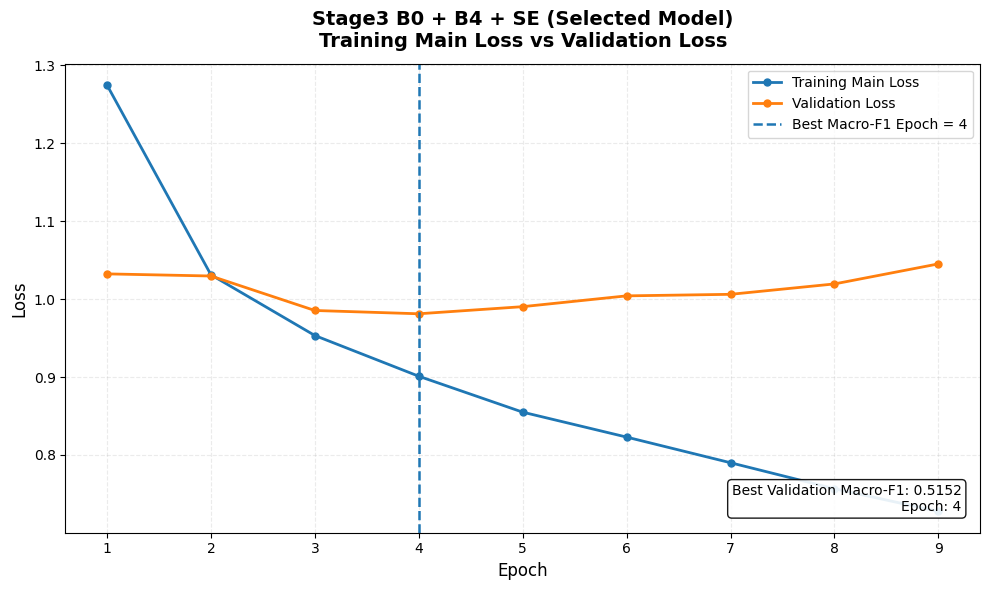

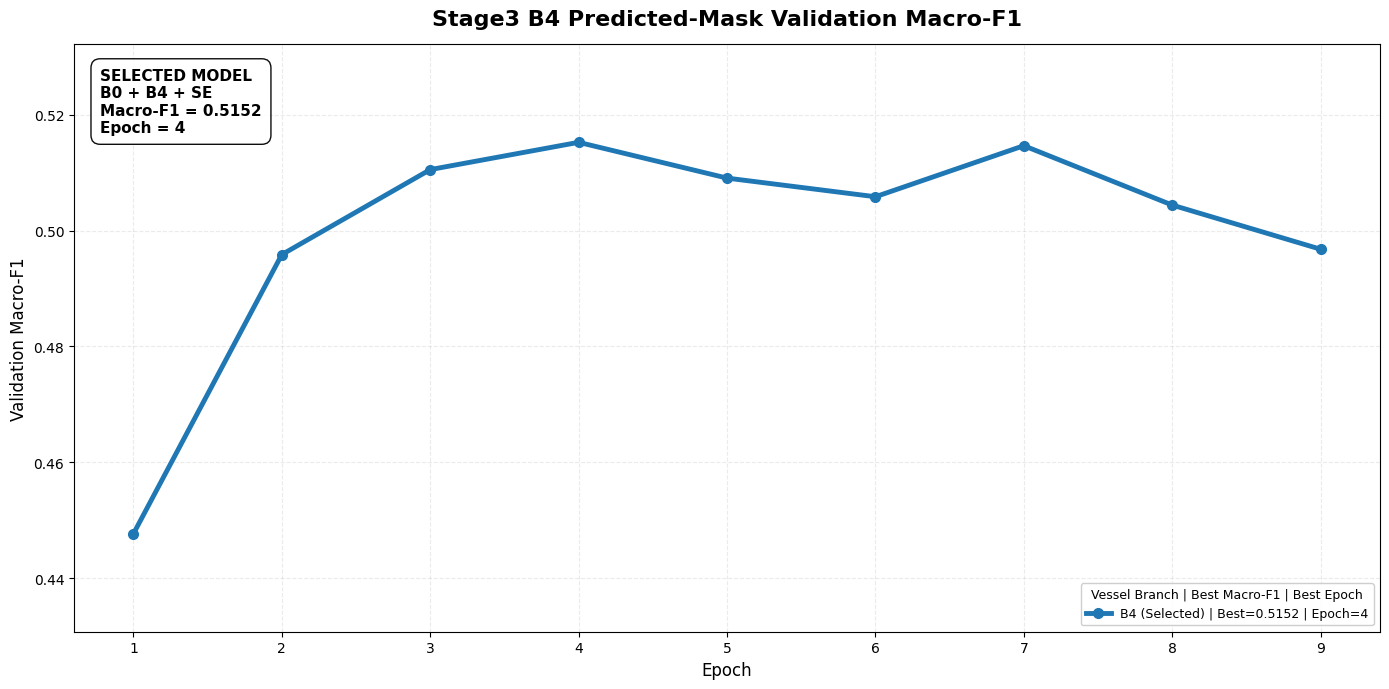


B1-B5 VALIDATION MACRO-F1 SUMMARY
Model  Best Validation Macro-F1  Best Epoch Selected
   B4                  0.515224           4      Yes

Selected model: B4

Training/validation loss plots:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/training_validation_curves

Validation Macro-F1 comparison plot:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/training_validation_curves/stage3_B1_B5_validation_macro_f1_model_selection.png

Validation Macro-F1 summary CSV:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/training_validation_curves/stage3_B1_B5_best_validation_macro_f1_summary.csv


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


STAGE3_DIR = OUT_DIR


CURVE_DIR = os.path.join(
    STAGE3_DIR,
    "training_validation_curves"
)


os.makedirs(
    CURVE_DIR,
    exist_ok=True
)


MODELS = ["B4"]


SELECTED_FILE = os.path.join(
    STAGE3_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)


BEST_MODEL = None


if os.path.exists(
    SELECTED_FILE
):

    selected_df = pd.read_csv(
        SELECTED_FILE
    )

    if not selected_df.empty:

        BEST_MODEL = str(
            selected_df.iloc[0][
                "selected_model"
            ]
        )


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        print(
            f"{model_name}: history file not found."
        )

        continue


    history_df = pd.read_csv(
        history_file
    )


    required_columns = {
        "epoch",
        "train_main_loss",
        "val_loss",
        "val_macro_f1"
    }


    if (
        history_df.empty
        or
        not required_columns.issubset(
            history_df.columns
        )
    ):

        print(
            f"{model_name}: required history data missing."
        )

        continue


    epochs = history_df[
        "epoch"
    ].values


    train_main_loss = history_df[
        "train_main_loss"
    ].values


    val_loss = history_df[
        "val_loss"
    ].values


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            6
        )
    )


    ax.plot(
        epochs,
        train_main_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Training Main Loss"
    )


    ax.plot(
        epochs,
        val_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Validation Loss"
    )


    ax.axvline(
        best_epoch,
        linestyle="--",
        linewidth=1.8,
        label=(
            f"Best Macro-F1 Epoch = "
            f"{best_epoch}"
        )
    )


    if (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    ):

        title = (
            f"Stage3 B0 + {model_name} + SE "
            "(Selected Model)\n"
            "Training Main Loss vs Validation Loss"
        )

    else:

        title = (
            f"Stage3 B0 + {model_name} + SE\n"
            "Training Main Loss vs Validation Loss"
        )


    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )


    ax.set_xlabel(
        "Epoch",
        fontsize=12
    )


    ax.set_ylabel(
        "Loss",
        fontsize=12
    )


    ax.set_xticks(
        epochs
    )


    ax.tick_params(
        axis="both",
        labelsize=10
    )


    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )


    ax.legend(
        loc="best",
        fontsize=10,
        frameon=True
    )


    ax.text(
        0.98,
        0.04,
        (
            f"Best Validation Macro-F1: "
            f"{best_f1:.4f}\n"
            f"Epoch: {best_epoch}"
        ),
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="black",
            alpha=0.9
        )
    )


    plt.tight_layout()


    loss_plot_path = os.path.join(
        CURVE_DIR,
        f"stage3_{model_name}_training_vs_validation_loss.png"
    )


    plt.savefig(
        loss_plot_path,
        dpi=220,
        bbox_inches="tight"
    )


    plt.show()


    plt.close(
        fig
    )


fig, ax = plt.subplots(
    figsize=(
        14,
        7
    )
)


all_f1_values = []

max_epoch = 0

selected_best_epoch = None

selected_best_f1 = None

model_summary = []


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        continue


    history_df = pd.read_csv(
        history_file
    )


    if (
        history_df.empty
        or
        "epoch" not in history_df.columns
        or
        "val_macro_f1" not in history_df.columns
    ):

        continue


    epochs = history_df[
        "epoch"
    ].values


    val_macro_f1 = history_df[
        "val_macro_f1"
    ].values


    all_f1_values.extend(
        val_macro_f1.tolist()
    )


    max_epoch = max(
        max_epoch,
        int(
            np.max(
                epochs
            )
        )
    )


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    is_selected = (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    )


    if is_selected:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=7,
            linewidth=3.5,
            zorder=5,
            label=(
                f"{model_name} (Selected) | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


        selected_best_epoch = (
            best_epoch
        )


        selected_best_f1 = (
            best_f1
        )


    else:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=5,
            linewidth=1.8,
            alpha=0.80,
            label=(
                f"{model_name} | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


    model_summary.append(
        {
            "Model":
                model_name,

            "Best Validation Macro-F1":
                best_f1,

            "Best Epoch":
                best_epoch,

            "Selected":
                (
                    "Yes"
                    if is_selected
                    else "No"
                )
        }
    )


if len(
    all_f1_values
) == 0:

    raise RuntimeError(
        "No validation Macro-F1 history found."
    )


y_min = min(
    all_f1_values
)


y_max = max(
    all_f1_values
)


y_range = (
    y_max
    -
    y_min
)


y_padding = max(
    0.01,
    y_range * 0.25
)


ax.set_ylim(
    max(
        0,
        y_min - y_padding
    ),
    min(
        1,
        y_max + y_padding
    )
)


if max_epoch > 0:

    ax.set_xticks(
        np.arange(
            1,
            max_epoch + 1,
            1
        )
    )


ax.set_title(
    "Stage3 B4 Predicted-Mask Validation Macro-F1",
    fontsize=16,
    fontweight="bold",
    pad=14
)


ax.set_xlabel(
    "Epoch",
    fontsize=12
)


ax.set_ylabel(
    "Validation Macro-F1",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)


ax.legend(
    title=(
        "Vessel Branch | "
        "Best Macro-F1 | Best Epoch"
    ),
    loc="lower right",
    fontsize=9,
    title_fontsize=9,
    frameon=True,
    framealpha=0.95
)


if (
    selected_best_epoch is not None
    and
    selected_best_f1 is not None
):

    ax.text(
        0.02,
        0.96,
        (
            f"SELECTED MODEL\n"
            f"B0 + {BEST_MODEL} + SE\n"
            f"Macro-F1 = "
            f"{selected_best_f1:.4f}\n"
            f"Epoch = "
            f"{selected_best_epoch}"
        ),
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )


plt.tight_layout()


macro_f1_plot_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_validation_macro_f1_model_selection.png"
)


plt.savefig(
    macro_f1_plot_path,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


model_summary_df = pd.DataFrame(
    model_summary
)


model_summary_df = (
    model_summary_df
    .sort_values(
        by=[
            "Best Validation Macro-F1"
        ],
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


summary_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_best_validation_macro_f1_summary.csv"
)


model_summary_df.to_csv(
    summary_path,
    index=False
)


print(
    "\n"
    + "=" * 80
)


print(
    "B1-B5 VALIDATION MACRO-F1 SUMMARY"
)


print(
    "=" * 80
)


print(
    model_summary_df.to_string(
        index=False
    )
)


print(
    "\nSelected model:",
    BEST_MODEL
)


print(
    "\nTraining/validation loss plots:"
)


print(
    CURVE_DIR
)


print(
    "\nValidation Macro-F1 comparison plot:"
)


print(
    macro_f1_plot_path
)


print(
    "\nValidation Macro-F1 summary CSV:"
)


print(
    summary_path
)


SELECTED MODEL FROM VALIDATION
Model: B0 + B4 + SE
Best validation epoch: 4
Validation Macro-F1: 0.5152
Checkpoint:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/stage3_B4_best.pth

Selected Stage3 model loaded successfully.

FINAL TEST SET VERIFICATION
Stage1 final test images: 5269
Stage3 final test images: 5269
Same exact test IDs: True
Same exact test IDs and order: True
Stage1-only IDs: 0
Stage3-only IDs: 0

STAGE1 TEST


Stage1 Test:   0%|          | 0/83 [00:00<?, ?batch/s]


STAGE3 TEST: B0 + B4 + SE


Stage3 B0+B4+SE Test:   0%|          | 0/659 [00:00<?, ?batch/s]


Stage1 and Stage3 test labels/order match: True

STAGE1 - RGB ONLY
                  precision    recall  f1-score   support

           no_dr     0.8409    0.8657    0.8531      3872
            mild     0.1250    0.1557    0.1387       366
        moderate     0.5303    0.4521    0.4881       794
          severe     0.5000    0.3053    0.3791       131
proliferative_dr     0.7714    0.5094    0.6136       106

        accuracy                         0.7330      5269
       macro avg     0.5535    0.4577    0.4945      5269
    weighted avg     0.7345    0.7330    0.7319      5269

Accuracy        = 0.7330
Macro-F1        = 0.4945
Weighted-F1     = 0.7319
Macro Precision = 0.5535
Macro Recall    = 0.4577
Macro-AUROC     = 0.8122

STAGE3 - RGB B0 + B4 VESSEL + SE
                  precision    recall  f1-score   support

           no_dr     0.8380    0.9419    0.8869      3872
            mild     0.1898    0.0710    0.1034       366
        moderate     0.5897    0.4471    0.5086 

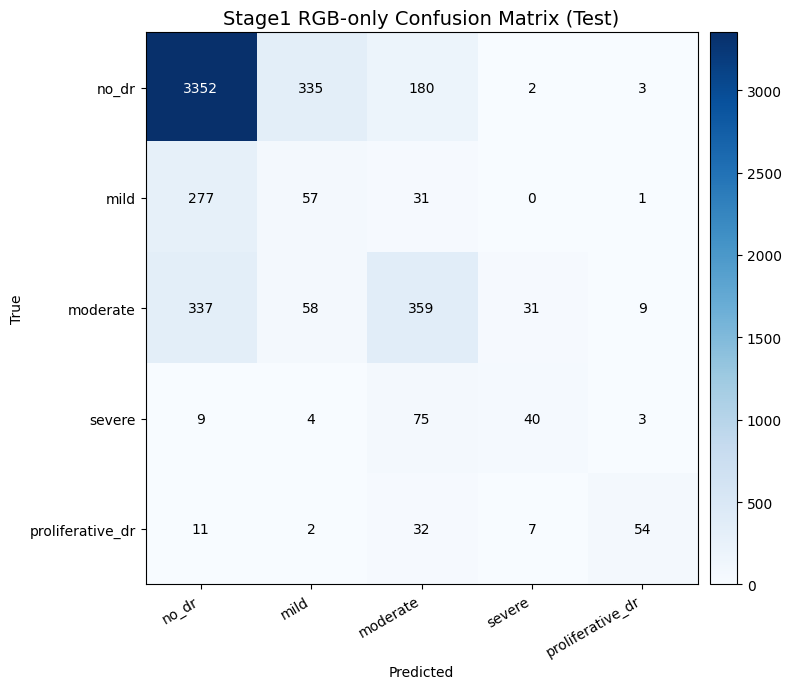

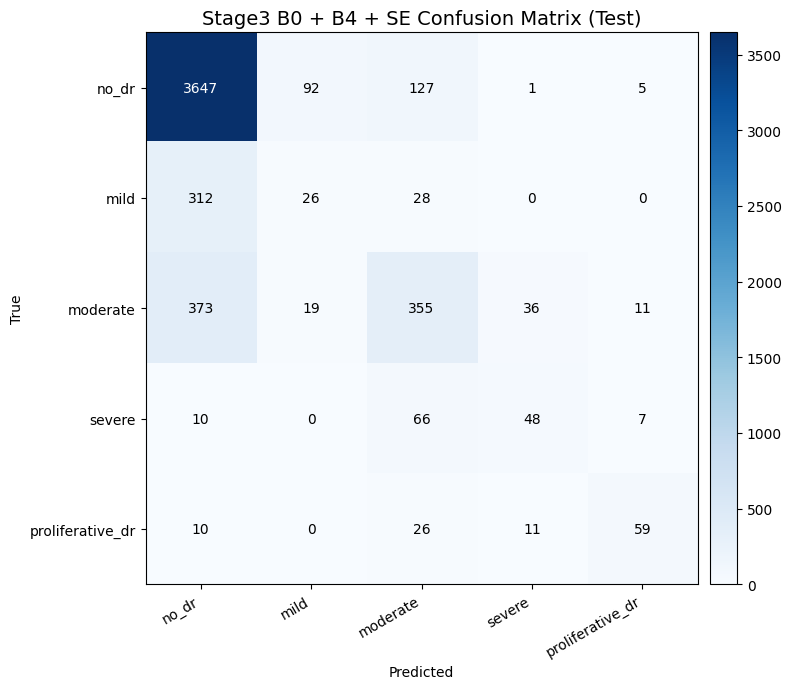

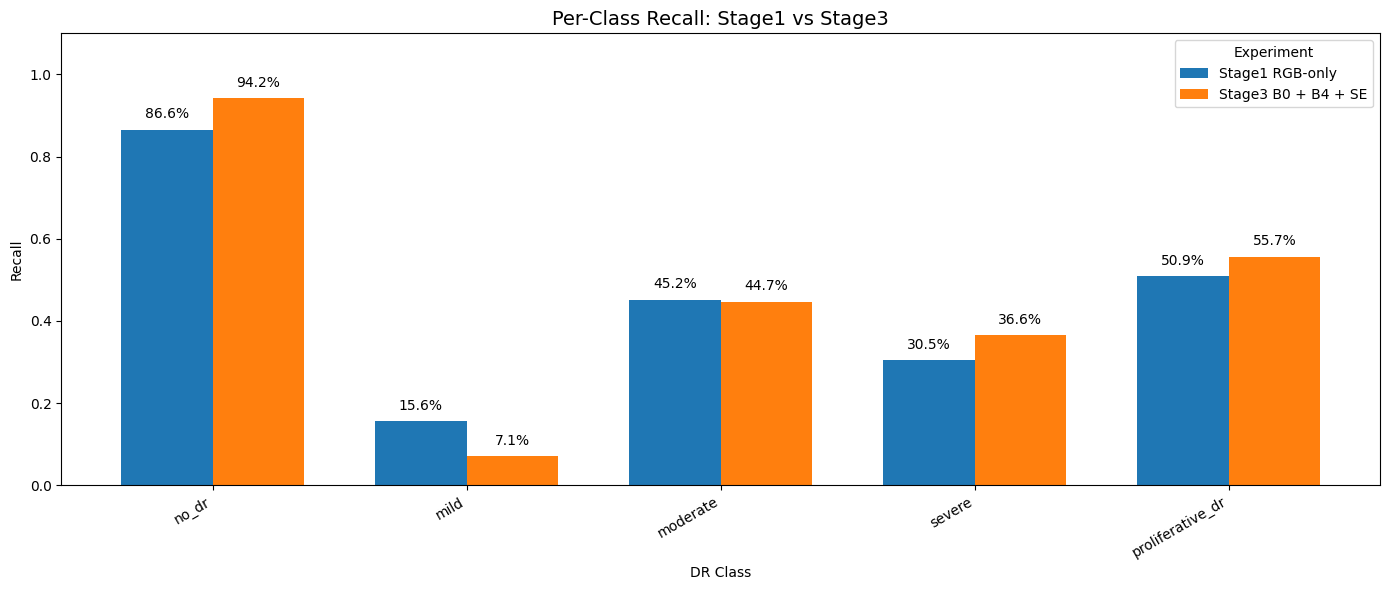


FINAL TESTING COMPLETED

Selected model: B0 + B4 + SE
Stage3 Test Accuracy: 0.7848
Stage3 Test Macro-F1: 0.5099
Stage3 Test Weighted-F1: 0.7587
Stage3 Test Macro-Precision: 0.5674
Stage3 Test Macro-Recall: 0.4766
Stage3 Test Macro-AUROC: 0.8196

Stage1 confusion matrix:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/final_test_results/stage1_confusion_matrix.png

Stage3 confusion matrix:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/final_test_results/stage3_B0_B4_SE_confusion_matrix.png

Per-class recall plot:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/final_test_results/per_class_recall_comparison.png

Selected test CSV:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/SELECTED_MODEL_FINAL_TEST.csv
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_predicted_mask_SE/final_test_results


In [14]:
import os
import shutil
import warnings

import numpy as np
import pandas as pd

import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.preprocessing import (
    label_binarize
)

from mpl_toolkits.axes_grid1 import make_axes_locatable


warnings.filterwarnings(
    "ignore",
    message="Mapping deprecated model name.*"
)


required_items = [
    "Stage3EfficientNetB0BxSE",
    "stage1",
    "df_stage3",
    "test_df",
    "stage3_test_ds",
    "DRStage3Dataset",
    "STAGE3_SIZE",
    "STAGE3_BATCH",
    "STAGE3_NUM_WORKERS",
    "PIN_MEMORY",
    "CLASS_NAMES",
    "num_classes",
    "device",
    "STAGE1_W"
]


missing = [
    name
    for name in required_items
    if name not in globals()
]


if missing:
    raise RuntimeError(
        "Missing required testing variables: "
        + ", ".join(missing)
    )


AMP_DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


def macro_auroc(
    y_true,
    y_probs,
    num_classes
):
    try:
        y_true_bin = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return float(
            roc_auc_score(
                y_true_bin,
                y_probs,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception as e:
        print(
            "AUROC calculation warning:",
            e
        )

        return np.nan


if "DRIVE_COMPARE_DIR" not in globals():
    DRIVE_COMPARE_DIR = (
        "/content/drive/MyDrive/DR_Project/"
        "stage3_b1_b5_comparison_with_val_loss"
    )


FINAL_DIR = os.path.join(OUT_DIR, "final_test_results")


os.makedirs(
    FINAL_DIR,
    exist_ok=True
)


selected_validation_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)


if not os.path.exists(
    selected_validation_csv
):
    raise FileNotFoundError(
        "SELECTED_MODEL_VALIDATION.csv not found."
    )


selected_info = pd.read_csv(
    selected_validation_csv
).iloc[0]


BEST_MODEL = str(
    selected_info[
        "selected_model"
    ]
)


BEST_TIMM_MODEL = str(
    selected_info[
        "timm_model"
    ]
)


BEST_CHECKPOINT = str(
    selected_info[
        "checkpoint"
    ]
)


BEST_BATCH_SIZE = int(
    selected_info[
        "batch_size"
    ]
)


print(
    "\n"
    + "=" * 80
)


print(
    "SELECTED MODEL FROM VALIDATION"
)


print(
    "=" * 80
)


print(
    f"Model: B0 + {BEST_MODEL} + SE"
)


print(
    f"Best validation epoch: "
    f"{int(selected_info['best_epoch'])}"
)


print(
    f"Validation Macro-F1: "
    f"{selected_info['validation_macro_f1']:.4f}"
)


print(
    "Checkpoint:"
)


print(
    BEST_CHECKPOINT
)


if not os.path.exists(
    BEST_CHECKPOINT
):
    raise FileNotFoundError(
        BEST_CHECKPOINT
    )


LOCAL_STAGE1_W = os.path.join(
    "/content",
    os.path.basename(
        STAGE1_W
    )
)


if not os.path.exists(
    LOCAL_STAGE1_W
):
    shutil.copy2(
        STAGE1_W,
        LOCAL_STAGE1_W
    )


LOCAL_BEST_CHECKPOINT = os.path.join(
    "/content",
    f"selected_stage3_{BEST_MODEL}.pth"
)


shutil.copy2(
    BEST_CHECKPOINT,
    LOCAL_BEST_CHECKPOINT
)


stage3_clf = Stage3EfficientNetB0BxSE(
    num_classes,
    LOCAL_STAGE1_W,
    BEST_TIMM_MODEL,
    mask_pretrained=False
).to(
    device
)


if torch.cuda.is_available():
    stage3_clf = stage3_clf.to(
        memory_format=
            torch.channels_last
    )


stage3_clf.load_state_dict(
    torch.load(
        LOCAL_BEST_CHECKPOINT,
        map_location=device
    )
)


stage1.eval()

stage3_clf.eval()


print(
    "\nSelected Stage3 model loaded successfully."
)


if "stage1_test_names" not in globals():

    if "SPLIT_DIR" not in globals():
        raise RuntimeError(
            "SPLIT_DIR is missing."
        )

    stage1_test_file = os.path.join(
        SPLIT_DIR,
        "stage1_test_names.txt"
    )

    if not os.path.exists(
        stage1_test_file
    ):
        raise FileNotFoundError(
            stage1_test_file
        )

    with open(
        stage1_test_file,
        "r"
    ) as f:
        stage1_test_names = set(
            line.strip()
            for line in f
            if line.strip()
        )


df_stage1_test = (
    df_stage3[
        df_stage3[
            "basename"
        ].isin(
            stage1_test_names
        )
    ]
    .reset_index(
        drop=True
    )
)


stage1_final_test_ids = (
    df_stage1_test[
        "basename"
    ]
    .astype(str)
    .tolist()
)


stage3_final_test_ids = (
    test_df[
        "basename"
    ]
    .astype(str)
    .tolist()
)


if len(stage1_final_test_ids) != len(
    stage1_test_names
):
    raise RuntimeError(
        "Stage1 final test image count does not "
        "match stage1_test_names.txt."
    )


if len(stage3_final_test_ids) != len(
    stage1_test_names
):
    raise RuntimeError(
        "Stage3 final test image count does not "
        "match stage1_test_names.txt."
    )


if set(
    stage1_final_test_ids
) != stage1_test_names:
    raise RuntimeError(
        "Stage1 final test IDs do not exactly "
        "match stage1_test_names.txt."
    )


if set(
    stage3_final_test_ids
) != stage1_test_names:
    raise RuntimeError(
        "Stage3 final test IDs do not exactly "
        "match stage1_test_names.txt."
    )


if (
    stage1_final_test_ids
    !=
    stage3_final_test_ids
):
    raise RuntimeError(
        "Stage1 and Stage3 final test image "
        "IDs/order do not match."
    )


print(
    "\n"
    + "=" * 80
)


print(
    "FINAL TEST SET VERIFICATION"
)


print(
    "=" * 80
)


print(
    "Stage1 final test images:",
    len(stage1_final_test_ids)
)


print(
    "Stage3 final test images:",
    len(stage3_final_test_ids)
)


print(
    "Same exact test IDs:",
    set(stage1_final_test_ids)
    ==
    set(stage3_final_test_ids)
)


print(
    "Same exact test IDs and order:",
    stage1_final_test_ids
    ==
    stage3_final_test_ids
)


print(
    "Stage1-only IDs:",
    len(
        set(stage1_final_test_ids)
        -
        set(stage3_final_test_ids)
    )
)


print(
    "Stage3-only IDs:",
    len(
        set(stage3_final_test_ids)
        -
        set(stage1_final_test_ids)
    )
)


stage1_test_ds = DRStage3Dataset(
    df_stage1_test,
    size=STAGE3_SIZE,
    augment=False
)


stage1_loader_args = {
    "batch_size":
        STAGE3_BATCH,

    "shuffle":
        False,

    "num_workers":
        STAGE3_NUM_WORKERS,

    "pin_memory":
        PIN_MEMORY
}


if STAGE3_NUM_WORKERS > 0:
    stage1_loader_args[
        "persistent_workers"
    ] = True

    stage1_loader_args[
        "prefetch_factor"
    ] = 2


stage1_test_loader = DataLoader(
    stage1_test_ds,
    **stage1_loader_args
)


print(
    "\n"
    + "=" * 80
)


print(
    "STAGE1 TEST"
)


print(
    "=" * 80
)


s1_labels = []

s1_preds = []

s1_probs = []


with torch.inference_mode():

    stage1_pbar = tqdm(
        stage1_test_loader,
        desc="Stage1 Test",
        unit="batch",
        dynamic_ncols=True
    )

    for (
        rgb,
        mask,
        labels
    ) in stage1_pbar:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )

        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,

            enabled=
                torch.cuda.is_available()
        ):

            logits_s1 = stage1(
                rgb
            )

            probs_s1 = torch.softmax(
                logits_s1,
                dim=1
            )

        s1_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        s1_preds.extend(
            logits_s1
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        s1_probs.extend(
            probs_s1
            .detach()
            .cpu()
            .numpy()
        )


s1_labels = np.array(
    s1_labels
)


s1_preds = np.array(
    s1_preds
)


s1_probs = np.array(
    s1_probs
)


stage3_loader_args = {
    "batch_size":
        BEST_BATCH_SIZE,

    "shuffle":
        False,

    "num_workers":
        STAGE3_NUM_WORKERS,

    "pin_memory":
        PIN_MEMORY
}


if STAGE3_NUM_WORKERS > 0:
    stage3_loader_args[
        "persistent_workers"
    ] = True

    stage3_loader_args[
        "prefetch_factor"
    ] = 4


stage3_test_loader = DataLoader(
    stage3_test_ds,
    **stage3_loader_args
)


print(
    "\n"
    + "=" * 80
)


print(
    f"STAGE3 TEST: "
    f"B0 + {BEST_MODEL} + SE"
)


print(
    "=" * 80
)


s3_labels = []

s3_preds = []

s3_probs = []


with torch.inference_mode():

    stage3_pbar = tqdm(
        stage3_test_loader,
        desc=(
            f"Stage3 B0+{BEST_MODEL}+SE Test"
        ),
        unit="batch",
        dynamic_ncols=True
    )

    for (
        rgb,
        mask,
        labels
    ) in stage3_pbar:

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )

        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,

            enabled=
                torch.cuda.is_available()
        ):

            logits_s3 = stage3_clf(
                rgb,
                mask
            )

            probs_s3 = torch.softmax(
                logits_s3,
                dim=1
            )

        s3_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        s3_preds.extend(
            logits_s3
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        s3_probs.extend(
            probs_s3
            .detach()
            .cpu()
            .numpy()
        )


s3_labels = np.array(
    s3_labels
)


s3_preds = np.array(
    s3_preds
)


s3_probs = np.array(
    s3_probs
)


if not np.array_equal(
    s1_labels,
    s3_labels
):
    raise RuntimeError(
        "Stage1 and Stage3 test labels/order do not match."
    )


print(
    "\nStage1 and Stage3 test labels/order match:",
    True
)


S1_ACC = accuracy_score(
    s1_labels,
    s1_preds
)


S1_F1 = f1_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_F1W = f1_score(
    s1_labels,
    s1_preds,
    average="weighted",
    zero_division=0
)


S1_PRECISION = precision_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_MACRO_RECALL = recall_score(
    s1_labels,
    s1_preds,
    average="macro",
    zero_division=0
)


S1_AUC = macro_auroc(
    s1_labels,
    s1_probs,
    num_classes
)


S1_RECALL = recall_score(
    s1_labels,
    s1_preds,
    average=None,
    labels=list(
        range(
            num_classes
        )
    ),
    zero_division=0
)


CM1 = confusion_matrix(
    s1_labels,
    s1_preds,
    labels=list(
        range(
            num_classes
        )
    )
)


S3_ACC = accuracy_score(
    s3_labels,
    s3_preds
)


S3_F1 = f1_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_F1W = f1_score(
    s3_labels,
    s3_preds,
    average="weighted",
    zero_division=0
)


S3_PRECISION = precision_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_MACRO_RECALL = recall_score(
    s3_labels,
    s3_preds,
    average="macro",
    zero_division=0
)


S3_AUC = macro_auroc(
    s3_labels,
    s3_probs,
    num_classes
)


S3_RECALL = recall_score(
    s3_labels,
    s3_preds,
    average=None,
    labels=list(
        range(
            num_classes
        )
    ),
    zero_division=0
)


CM3 = confusion_matrix(
    s3_labels,
    s3_preds,
    labels=list(
        range(
            num_classes
        )
    )
)


print(
    "\n"
    + "=" * 70
)


print(
    "STAGE1 - RGB ONLY"
)


print(
    "=" * 70
)


print(
    classification_report(
        s1_labels,
        s1_preds,
        target_names=
            CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


print(
    f"Accuracy        = "
    f"{S1_ACC:.4f}"
)


print(
    f"Macro-F1        = "
    f"{S1_F1:.4f}"
)


print(
    f"Weighted-F1     = "
    f"{S1_F1W:.4f}"
)


print(
    f"Macro Precision = "
    f"{S1_PRECISION:.4f}"
)


print(
    f"Macro Recall    = "
    f"{S1_MACRO_RECALL:.4f}"
)


print(
    f"Macro-AUROC     = "
    f"{S1_AUC:.4f}"
)


print(
    "\n"
    + "=" * 70
)


print(
    f"STAGE3 - RGB B0 + "
    f"{BEST_MODEL} VESSEL + SE"
)


print(
    "=" * 70
)


print(
    classification_report(
        s3_labels,
        s3_preds,
        target_names=
            CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


print(
    f"Accuracy        = "
    f"{S3_ACC:.4f}"
)


print(
    f"Macro-F1        = "
    f"{S3_F1:.4f}"
)


print(
    f"Weighted-F1     = "
    f"{S3_F1W:.4f}"
)


print(
    f"Macro Precision = "
    f"{S3_PRECISION:.4f}"
)


print(
    f"Macro Recall    = "
    f"{S3_MACRO_RECALL:.4f}"
)


print(
    f"Macro-AUROC     = "
    f"{S3_AUC:.4f}"
)


summary_df = pd.DataFrame(
    [
        {
            "Model":
                "Stage1 RGB-only",

            "Accuracy":
                S1_ACC,

            "Macro F1":
                S1_F1,

            "Weighted F1":
                S1_F1W,

            "Macro Precision":
                S1_PRECISION,

            "Macro Recall":
                S1_MACRO_RECALL,

            "Macro AUROC":
                S1_AUC
        },

        {
            "Model":
                f"Stage3 B0 + {BEST_MODEL} + SE",

            "Accuracy":
                S3_ACC,

            "Macro F1":
                S3_F1,

            "Weighted F1":
                S3_F1W,

            "Macro Precision":
                S3_PRECISION,

            "Macro Recall":
                S3_MACRO_RECALL,

            "Macro AUROC":
                S3_AUC
        }
    ]
)


print(
    "\n"
    + "=" * 70
)


print(
    "OVERALL TEST COMPARISON"
)


print(
    "=" * 70
)


print(
    summary_df.to_string(
        index=False
    )
)


recall_df = pd.DataFrame(
    {
        "Class":
            CLASS_NAMES,

        "Stage1 Recall":
            S1_RECALL,

        "Stage3 Recall":
            S3_RECALL,

        "Gain":
            S3_RECALL
            -
            S1_RECALL
    }
)


print(
    "\n"
    + "=" * 70
)


print(
    "PER-CLASS RECALL"
)


print(
    "=" * 70
)


print(
    recall_df.to_string(
        index=False
    )
)


summary_csv = os.path.join(
    FINAL_DIR,
    "overall_comparison.csv"
)


summary_df.to_csv(
    summary_csv,
    index=False
)


recall_csv = os.path.join(
    FINAL_DIR,
    "per_class_recall.csv"
)


recall_df.to_csv(
    recall_csv,
    index=False
)


selected_test_result = {
    "selected_model":
        BEST_MODEL,

    "timm_model":
        BEST_TIMM_MODEL,

    "validation_accuracy":
        selected_info[
            "validation_accuracy"
        ],

    "validation_macro_f1":
        selected_info[
            "validation_macro_f1"
        ],

    "validation_macro_auc":
        selected_info[
            "validation_macro_auc"
        ],

    "test_accuracy":
        S3_ACC,

    "test_macro_f1":
        S3_F1,

    "test_weighted_f1":
        S3_F1W,

    "test_macro_precision":
        S3_PRECISION,

    "test_macro_recall":
        S3_MACRO_RECALL,

    "test_macro_auc":
        S3_AUC,

    "checkpoint":
        BEST_CHECKPOINT
}


for (
    i,
    class_name
) in enumerate(
    CLASS_NAMES
):

    selected_test_result[
        f"test_recall_{class_name}"
    ] = S3_RECALL[
        i
    ]


selected_test_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_FINAL_TEST.csv"
)


pd.DataFrame(
    [
        selected_test_result
    ]
).to_csv(
    selected_test_csv,
    index=False
)


fig, ax = plt.subplots(
    figsize=(
        8,
        7
    )
)


im1 = ax.imshow(
    CM1,
    interpolation="nearest",
    cmap="Blues"
)


divider1 = make_axes_locatable(
    ax
)


cax1 = divider1.append_axes(
    "right",
    size="5%",
    pad=0.12
)


fig.colorbar(
    im1,
    cax=cax1
)


ax.set_title(
    "Stage1 RGB-only Confusion Matrix (Test)",
    fontsize=14
)


ax.set_xlabel(
    "Predicted"
)


ax.set_ylabel(
    "True"
)


ax.set_xticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_yticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_yticklabels(
    CLASS_NAMES
)


threshold1 = CM1.max() / 2.0


for i in range(
    CM1.shape[0]
):
    for j in range(
        CM1.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{CM1[i, j]:d}",
            ha="center",
            va="center",
            color=(
                "white"
                if CM1[i, j] > threshold1
                else "black"
            )
        )


plt.tight_layout()


cm1_plot = os.path.join(
    FINAL_DIR,
    "stage1_confusion_matrix.png"
)


plt.savefig(
    cm1_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


fig, ax = plt.subplots(
    figsize=(
        8,
        7
    )
)


im3 = ax.imshow(
    CM3,
    interpolation="nearest",
    cmap="Blues"
)


divider3 = make_axes_locatable(
    ax
)


cax3 = divider3.append_axes(
    "right",
    size="5%",
    pad=0.12
)


fig.colorbar(
    im3,
    cax=cax3
)


ax.set_title(
    f"Stage3 B0 + {BEST_MODEL} + SE Confusion Matrix (Test)",
    fontsize=14
)


ax.set_xlabel(
    "Predicted"
)


ax.set_ylabel(
    "True"
)


ax.set_xticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_yticks(
    np.arange(
        len(CLASS_NAMES)
    )
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_yticklabels(
    CLASS_NAMES
)


threshold3 = CM3.max() / 2.0


for i in range(
    CM3.shape[0]
):
    for j in range(
        CM3.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{CM3[i, j]:d}",
            ha="center",
            va="center",
            color=(
                "white"
                if CM3[i, j] > threshold3
                else "black"
            )
        )


plt.tight_layout()


cm3_plot = os.path.join(
    FINAL_DIR,
    f"stage3_B0_{BEST_MODEL}_SE_confusion_matrix.png"
)


plt.savefig(
    cm3_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


x = np.arange(
    len(
        CLASS_NAMES
    )
)


width = 0.36


fig, ax = plt.subplots(
    figsize=(
        14,
        6
    )
)


bars1 = ax.bar(
    x - width / 2,
    S1_RECALL,
    width,
    label="Stage1 RGB-only"
)


bars2 = ax.bar(
    x + width / 2,
    S3_RECALL,
    width,
    label=(
        f"Stage3 B0 + {BEST_MODEL} + SE"
    )
)


ax.set_title(
    "Per-Class Recall: Stage1 vs Stage3",
    fontsize=14
)


ax.set_xlabel(
    "DR Class"
)


ax.set_ylabel(
    "Recall"
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    CLASS_NAMES,
    rotation=30,
    ha="right"
)


ax.set_ylim(
    0,
    1.10
)


ax.legend(
    title="Experiment"
)


for bar in bars1:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )


for bar in bars2:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )


plt.tight_layout()


recall_plot = os.path.join(
    FINAL_DIR,
    "per_class_recall_comparison.png"
)


plt.savefig(
    recall_plot,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


stage3_xai = stage3_clf


print(
    "\n"
    + "=" * 100
)


print(
    "FINAL TESTING COMPLETED"
)


print(
    "=" * 100
)


print(
    f"\nSelected model: "
    f"B0 + {BEST_MODEL} + SE"
)


print(
    f"Stage3 Test Accuracy: "
    f"{S3_ACC:.4f}"
)


print(
    f"Stage3 Test Macro-F1: "
    f"{S3_F1:.4f}"
)


print(
    f"Stage3 Test Weighted-F1: "
    f"{S3_F1W:.4f}"
)


print(
    f"Stage3 Test Macro-Precision: "
    f"{S3_PRECISION:.4f}"
)


print(
    f"Stage3 Test Macro-Recall: "
    f"{S3_MACRO_RECALL:.4f}"
)


print(
    f"Stage3 Test Macro-AUROC: "
    f"{S3_AUC:.4f}"
)


print(
    "\nStage1 confusion matrix:"
)


print(
    cm1_plot
)


print(
    "\nStage3 confusion matrix:"
)


print(
    cm3_plot
)


print(
    "\nPer-class recall plot:"
)


print(
    recall_plot
)


print(
    "\nSelected test CSV:"
)


print(
    selected_test_csv
)




print(
    FINAL_DIR
)